In [1]:
# Only in Colab: work inside the homework folder of Drive (the .py files are there)
import os
import sys
from pathlib import Path
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir("/content/drive/MyDrive/POSGRADOS/HUNGRIA/MASTER/1/FNANCIAL PROCESS /HOMEWORKS/3_HW_LECTURE_5")
except ImportError:
    pass
# the library imports src.enums: put this folder and the repository folder that contains src/ on the path
here = Path.cwd()
root = next((p for p in [here, *here.parents] if (p / 'src' / 'enums.py').exists()), here)
sys.path[:0] = [str(here), str(root)]
print('folder:', here.name, '| repository:', root.name)

folder: 3_HW_LECTURE_5 | repository: QuantCourseBP


**Homework 3: Digital options. Q2: the digital call as a limit of bull call spreads**

*Get familiar with bull spread options and by utilizing EuropeanDigitalAnalyticPricer and EuropeanAnalyticPricer, create a figure to visualize that a digital call option can be thought of as a limit of bull spread call options.* (8 points)

Bull call spread of width $h$: LONG call with strike $K$ + SHORT call with strike $K+h$; it pays at most $h$, so we hold $1/h$ of it.
Its payoff tends to $\mathbf{1}\{S_T>K\}$ and its price $R_h = \big(c(K)-c(K+h)\big)/h$ tends to $C_d = e^{-r\tau}N(d_2)$ (Lemma 4 of the report);
the left spread $L_h = \big(c(K-h)-c(K)\big)/h$ stays above $C_d$. Running example: `BLUECHIP_BANK`, $K = 130$, $T = 1$.

**Code used** (files of this folder): the library of Lecture 5 with the classes of Q1 (`pricer.py`, notebook `3_HW_EXE_1`) and `my_plotter` of Homework 1 (`plotter.py`)

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from pricer import *                                 # library of Lecture 5 + the classes of Q1
from plotter import my_plotter                       # Homework 1 (HW 2/1)

**Test of the code used**: a LONG call, a SHORT call and the digital call of the running example

In [3]:
# test: BLUECHIP_BANK, T = 1
model = MarketModel(Stock.BLUECHIP_BANK)
long_call = EuropeanAnalyticPricer(EuropeanContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, 130.0, 1.0), model, Params())
short_call = EuropeanAnalyticPricer(EuropeanContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.SHORT, 140.0, 1.0), model, Params())
digital_call = EuropeanDigitalAnalyticPricer(EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, 130.0, 1.0), model, Params())
print(f"long call K = 130: {long_call.calc_fair_value():.6f},  short call K = 140: {short_call.calc_fair_value():.6f},  digital call K = 130: {digital_call.calc_fair_value():.6f}")

long call K = 130: 22.601190,  short call K = 140: -18.427336,  digital call K = 130: 0.454437


**NEW CODE** (file `q2_bull_spread.py`): the bull spread as two pricers of the lecture (the SHORT leg has `direction` $=-1$, so the sum of the two fair values is the price of the spread), its scaled price and payoff, and a helper that prices at another spot

In [4]:
stock, strike, expiry = Stock.BLUECHIP_BANK, 130.0, 1.0
model = MarketModel(stock)


def bull_spread(k_low: float, k_high: float) -> list[EuropeanAnalyticPricer]:
    """Bull call spread (Definition 2): LONG call with strike k_low + SHORT call with strike k_high."""
    long_leg = EuropeanContract(stock, PutCallFwd.CALL, LongShort.LONG, k_low, expiry)
    short_leg = EuropeanContract(stock, PutCallFwd.CALL, LongShort.SHORT, k_high, expiry)
    return [EuropeanAnalyticPricer(long_leg, model, Params()), EuropeanAnalyticPricer(short_leg, model, Params())]


def scaled_value(legs: list[EuropeanAnalyticPricer], h: float) -> float:
    """Price of (1/h) x bull spread: the sum of the two legs (the SHORT leg is negative), divided by h."""
    return sum(leg.calc_fair_value() for leg in legs) / h


def scaled_payoff(legs: list[EuropeanAnalyticPricer], h: float, s_T: float) -> float:
    return sum(leg.contract.payoff({expiry: s_T}) for leg in legs) / h


def at_spot(pricer_value, s: float) -> float:
    """Value with the model's spot set to s (the model is shared by all pricers), then restore it."""
    base = model.spot
    model.spot = s
    value = pricer_value()
    model.spot = base
    return value


digital_contract = EuropeanDigitalContract(stock, PutCallFwd.CALL, LongShort.LONG, strike, expiry)
digital = EuropeanDigitalAnalyticPricer(digital_contract, model, Params())
c_d = digital.calc_fair_value()
print(f'market: S = {model.spot}, vol = {model.vol}, r = {model.risk_free_rate};  K = {strike}, T = {expiry}')
print(f'digital call C_d = {c_d:.6f}')

market: S = 130.17, vol = 0.381, r = 0.05;  K = 130.0, T = 1.0
digital call C_d = 0.454437


**Table**: $R_h \le C_d \le L_h$ for $h$ from 40 to 0.01, and the order of the error

In [5]:
# 1. table: right spread R_h = (1/h)(K, K+h) <= C_d <= left spread L_h = (1/h)(K-h, K)  (proof of Lemma 4)
print(f"{'h':>7s}{'R_h':>11s}{'L_h':>11s}{'C_d - R_h':>12s}{'L_h - C_d':>12s}")
widths = np.array([40.0, 20.0, 10.0, 5.0, 2.0, 1.0, 0.5, 0.1, 0.01])
right = np.array([scaled_value(bull_spread(strike, strike + h), h) for h in widths])
left = np.array([scaled_value(bull_spread(strike - h, strike), h) for h in widths])
for h, r_h, l_h in zip(widths, right, left):
    print(f'{h:7.2f}{r_h:11.6f}{l_h:11.6f}{c_d - r_h:12.2e}{l_h - c_d:12.2e}')
slope = np.polyfit(np.log(widths[-4:]), np.log(c_d - right[-4:]), 1)[0]
print(f'error of R_h ~ h^{slope:.2f} for small h (first order)')

      h        R_h        L_h   C_d - R_h   L_h - C_d
  40.00   0.322478   0.617161    1.32e-01    1.63e-01
  20.00   0.382947   0.534585    7.15e-02    8.01e-02
  10.00   0.417385   0.493716    3.71e-02    3.93e-02
   5.00   0.435603   0.473831    1.88e-02    1.94e-02
   2.00   0.446832   0.462131    7.60e-03    7.69e-03
   1.00   0.450623   0.458273    3.81e-03    3.84e-03
   0.50   0.452527   0.456352    1.91e-03    1.92e-03
   0.10   0.454054   0.454819    3.82e-04    3.83e-04
   0.01   0.454398   0.454475    3.82e-05    3.83e-05
error of R_h ~ h^1.00 for small h (first order)


**Figure**: (a) payoffs at expiry, (b) prices today against the spot, (c) the error against $h$ (saved in `figures/`)

figure saved: figures/q2_digital_vs_bull_spreads.pdf (and .png)


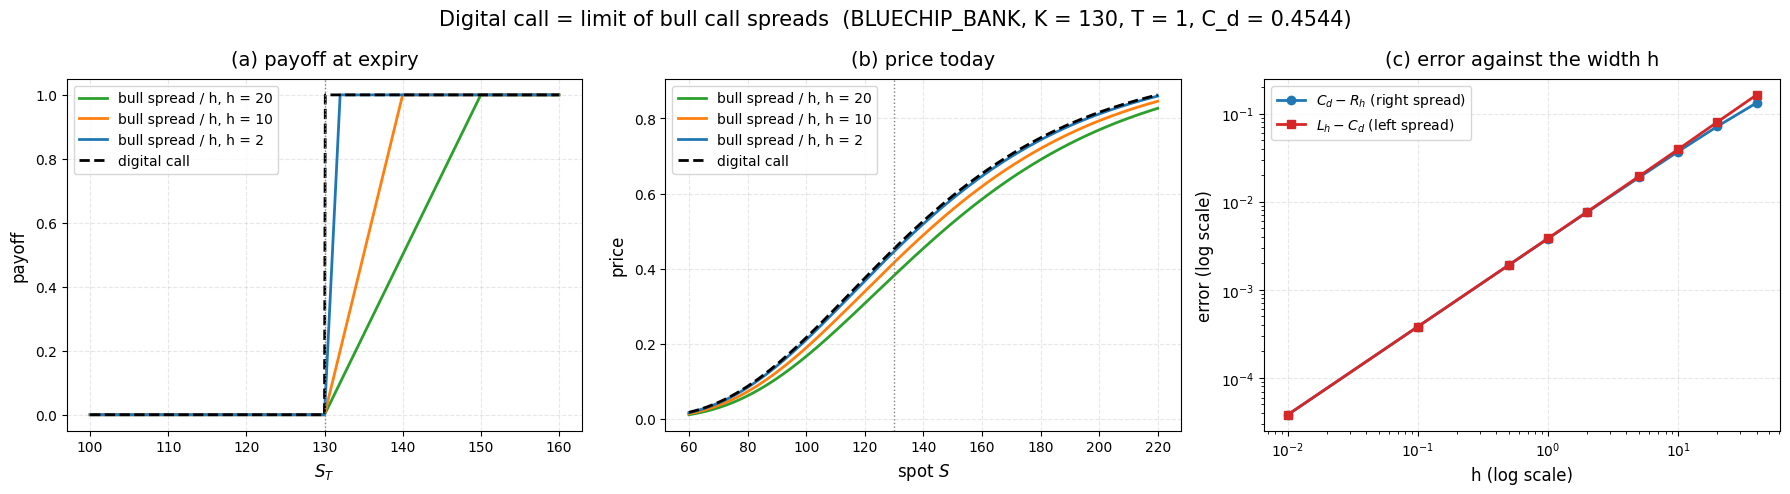

In [6]:
# 2. figure: (a) payoffs at T, (b) prices today against the spot, (c) price error against h
plot_widths = [20.0, 10.0, 2.0]
colors = ['tab:green', 'tab:orange', 'tab:blue', 'black']
names = [f'bull spread / h, h = {h:g}' for h in plot_widths] + ['digital call']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

s_T = np.linspace(100.0, 160.0, 601)
payoffs = [[scaled_payoff(bull_spread(strike, strike + h), h, s) for s in s_T] for h in plot_widths]
payoffs.append([digital.contract.payoff({expiry: s}) for s in s_T])
my_plotter(s_T, payoffs, names=names, ax=axes[0],
           layout={'title': '(a) payoff at expiry', 'x_label': '$S_T$', 'y_label': 'payoff',
                   'colors': colors, 'linestyles': ['-', '-', '-', '--'], 'linewidth': 2, 'title_fontsize': 14,
                   'label_fontsize': 12, 'legend_fontsize': 10, 'title_pad': 10, 'label_pad': 5,
                   'hline': None, 'vlines': [strike], 'grid': True, 'legend_loc': 'upper left'})

spots = np.linspace(60.0, 220.0, 161)
prices = [[at_spot(lambda: scaled_value(bull_spread(strike, strike + h), h), s) for s in spots] for h in plot_widths]
prices.append([at_spot(digital.calc_fair_value, s) for s in spots])
my_plotter(spots, prices, names=names, ax=axes[1],
           layout={'title': '(b) price today', 'x_label': 'spot $S$', 'y_label': 'price',
                   'colors': colors, 'linestyles': ['-', '-', '-', '--'], 'linewidth': 2, 'title_fontsize': 14,
                   'label_fontsize': 12, 'legend_fontsize': 10, 'title_pad': 10, 'label_pad': 5,
                   'hline': None, 'vlines': [strike], 'grid': True, 'legend_loc': 'upper left'})

my_plotter(widths, [c_d - right, left - c_d], names=['$C_d - R_h$ (right spread)', '$L_h - C_d$ (left spread)'],
           ax=axes[2],
           layout={'title': '(c) error against the width h', 'x_label': 'h (log scale)',
                   'y_label': 'error (log scale)', 'colors': ['tab:blue', 'tab:red'], 'markers': ['o', 's'],
                   'linewidth': 2, 'title_fontsize': 14, 'label_fontsize': 12, 'legend_fontsize': 10,
                   'title_pad': 10, 'label_pad': 5, 'hline': None, 'logx': True, 'logy': True, 'grid': True,
                   'legend_loc': 'upper left'})
fig.suptitle(f'Digital call = limit of bull call spreads  (BLUECHIP_BANK, K = {strike:g}, T = {expiry:g},'
             f' C_d = {c_d:.4f})', fontsize=15)
fig.tight_layout()
(here / 'figures').mkdir(exist_ok=True)
fig.savefig(here / 'figures' / 'q2_digital_vs_bull_spreads.pdf')
fig.savefig(here / 'figures' / 'q2_digital_vs_bull_spreads.png', dpi=110)
print('figure saved: figures/q2_digital_vs_bull_spreads.pdf (and .png)')
plt.show()

**Blocks after Q2**: the figure script (NEW) uses both pricers; all the blocks of the homework.

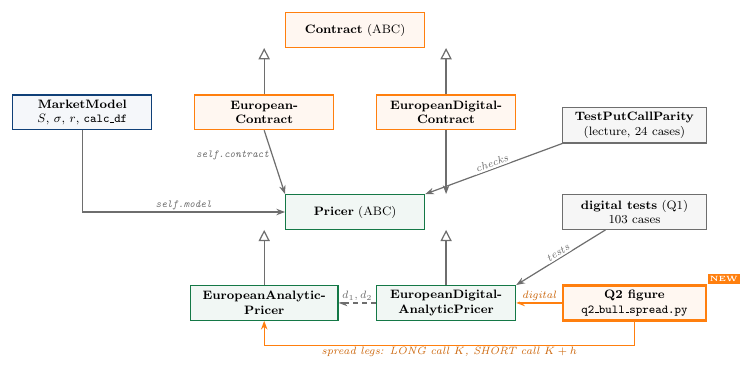